In [1]:
import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [3]:
file_location = os.path.join('C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs', '*.txt')
filenames = glob.glob(file_location)

In [4]:
filenames

['C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_1_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_2_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_3_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_4_29_1_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_4_29_2_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_4_29_3_1.txt']

### Setting to adjust umap density
#### Original values: 
* `init_dt = 0.01`
* `dt = 0.2`
* `window = 2`
* `time_step = 1`

#### umap params
* `neighbs = 50`
* `min_d = 0.05`


### Filenaming convention
Filename will incorporate parameter values in order above (not including umap parameters).

In [80]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 5                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.05
"""
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 5                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 150
min_d = 0.05

#reducer save name
r_name = f'\\reducer_05_01_{init_dt}_{dt}_{window}_{time_step}.sav'

'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_1_1.txt'

In [41]:
#Load and resample time based on umap window
time_tmp = pd.read_csv('t_4-9_3_3.txt', sep=",", header=None)
time_tmp = time_tmp.T
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])

In [42]:
def load_norm_data(filenames, time_file, init_dt, dt, window, time_step):
    time_tmp = pd.read_csv(time_file, sep=",", header=None)
    time_tmp = time_tmp.T
    time_tmp.columns = ["time"]
    time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
    
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp[prot_tmp<0] = 0
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames:
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
        prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
    return all_prot_tmp, all_time_tmp, all_time_at_tmp
        

In [74]:
all_prot_tmp, all_time_tmp, all_time_at_tmp = load_norm_data(filenames, 't_4-9_3_3.txt', init_dt, dt, window, time_step)

In [ ]:
all_time_at_tmp

In [84]:
len(all_prot_tmp)

29976

In [81]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(all_prot_tmp)

embedding_all_prot = reducer.transform(all_prot_tmp)

In [12]:
import matplotlib.pyplot as plt

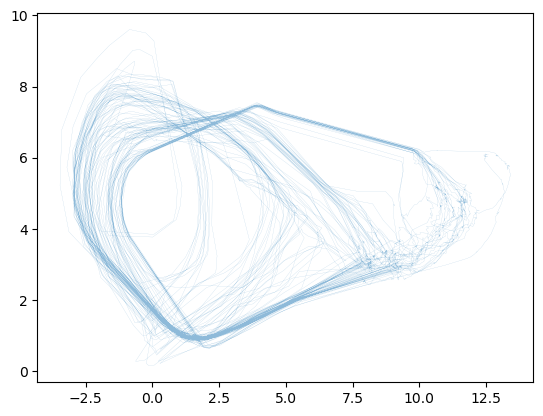

In [88]:
fig = plt.figure()
plt.plot(embedding_all_prot[4*4996:5*4996,0], embedding_all_prot[4*4996:5*4996,1], lw=0.1, alpha=0.5)

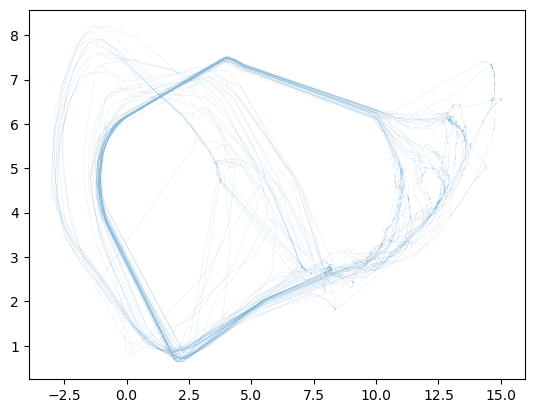

In [86]:
fig = plt.figure()
plt.plot(embedding_all_prot[3*4996:4*4996,0], embedding_all_prot[3*4996:4*4996,1], lw=0.1, alpha=0.5)

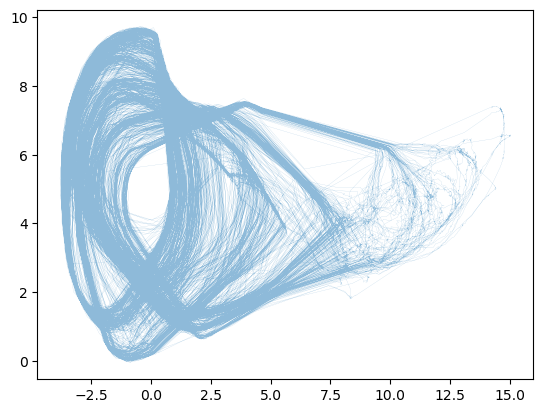

In [82]:
fig = plt.figure()
plt.plot(embedding_all_prot[:,0], embedding_all_prot[:,1], lw=0.1, alpha=0.5)

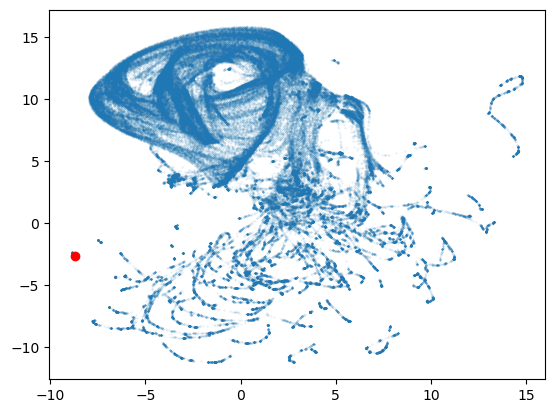

In [71]:
fig = plt.figure()
plt.scatter(embedding_all_prot[:,0], embedding_all_prot[:,1], s=0.1, alpha=0.2)
plt.scatter(embedding_all_prot[76985,0], embedding_all_prot[76985,1], c='red')

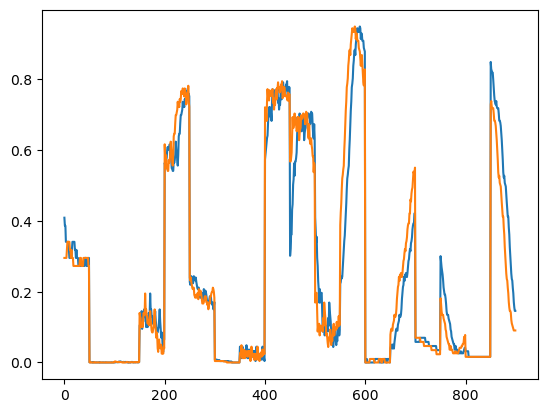

In [76]:
fig = plt.figure()
plt.plot(all_prot_tmp[10000,:])
plt.plot(all_prot_tmp[10001,:])

In [ ]:
fig = plt.figure()
plt.plot(embedding_all_prot[:5000,0], embedding_all_prot[:5000,1])

In [9]:
joblib.dump(reducer, str(SAVEDIR) + r_name)



['C:\\Users\\olesk\\ECM_mod_output\\UMAP\\reducer_09_25_0.01_0.02_1_0.2.sav']

In [1]:
import pandas as pd
import numpy as np
import umap
import glob
import os
import joblib
from pathlib import Path


In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [3]:
#The filenames to make the umaps from
filenames = ['erl_4-9_1_1.txt', # 'erl_4-9_1_2.txt', 'erl_4-9_1_3.txt',
             'erl_4-9_2_1.txt', # 'erl_4-9_2_2.txt', 'erl_4-9_2_3.txt',
             'erl_4-9_3_1.txt', # 'erl_4-9_3_2.txt', 'erl_4-9_3_3.txt',
             'dmso_4-9_1_1.txt', # 'dmso_4-9_1_2.txt', 'dmso_4-9_1_3.txt',
             'dmso_4-9_2_1.txt', # 'dmso_4-9_2_2.txt', 'dmso_4-9_2_3.txt',
             'dmso_4-9_3_1.txt'] # 'dmso_4-9_3_2.txt', 'dmso_4-9_3_3.txt']

In [14]:
file_location = os.path.join('C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs', '*.txt')
filenames = glob.glob(file_location)

In [15]:
filenames

['C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_1_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_2_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_3_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_1_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_2_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_3_1.txt']

In [16]:
#if you have a lot of data for umaps
"""
file_location = os.path.join('C:\\Users\Austin\Documents\\UMAP_projects\\nsclc_model\\22_02_14_runs\\', '*.txt')
filenames = glob.glob(file_location)
"""

#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 0.2                 #time step between windows

#umap params
neighbs = 50
min_d = 0.05
reducer = joblib.load(str(SAVEDIR) + f'\\reducer_04_10_{init_dt}_{dt}_{window}_{time_step}.sav')

In [11]:
#Load and resample time based on umap window
time_tmp = pd.read_csv('t_4-9_3_3.txt', sep=",", header=None)
time_tmp = time_tmp.T
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])

In [17]:
#create window and total protein arrays
win_len = int(window/dt)
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))


for f in filenames:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
    
    embedding_all_prot = reducer.transform(prot_re_tmp)
    split_s = f.split('.')
    split_ss = split_s[0].split('\\')
    name = split_ss[-1]+'.csv'
    
    np.savetxt(str(SAVEDIR) + f'\\embedding_{name}', embedding_all_prot, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_time_{name}', time_re_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_time_{name}', time_at_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_prot_{name}', prot_re_tmp, delimiter=',', fmt='%f')

In [21]:
#create window and total protein arrays using max vals
win_len = int(window/dt)
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))


max_prots=[0]*18
min_prots=[1000]*18

for f in filenames:
    tmp_max=[]
    tmp_min=[]
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp[prot_tmp<0] = 0

    tmp_max = [prot_tmp[col].max() for col in prot_tmp]
    tmp_min = [prot_tmp[col].min() for col in prot_tmp]

    max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
    min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]

for f in filenames:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    for ii in range(18):
        prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
    
    embedding_all_prot = reducer.transform(prot_re_tmp)
    split_s = f.split('.')
    name = 'embedding_erl_'+split_s[0]+'.csv'
    np.savetxt(str(SAVEDIR) + '\\embedding_'+split_s[0]+'.csv', embedding_all_prot, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + '\\all_time_'+split_s[0]+'.csv', time_re_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + '\\all_time_at_'+split_s[0]+'.csv', time_at_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + '\\all_prot_'+split_s[0]+'.csv', prot_re_tmp, delimiter=',', fmt='%f')

Change cycA inhibition of cycE rate parameter

In [ ]:
file_location = os.path.join('C:\\Program Files\\MATLAB\R2022a\\ECM_UMAP_output\\', 'prot_V*.csv')
filenames = glob.glob(file_location)

In [ ]:
filenames = [filenames[3]]
filenames

In [ ]:
#Load and resample time based on umap window
time_tmp = pd.read_csv('t_4-9_3_3.txt', sep=",", header=None)
time_tmp = time_tmp.T
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])

In [ ]:
#create window and total protein arrays
win_len = int(window/dt)
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))


for f in filenames:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
    
    embedding_all_prot = reducer.transform(prot_re_tmp)
    split_s = f.split('.')
    split_ss = split_s[0].split('\\')
    name = split_ss[-1]+'.csv'
    
    np.savetxt(str(SAVEDIR) + f'\\embedding_{name}' + '.csv', embedding_all_prot, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_time_{name}' + '.csv', time_re_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_time_{name}' + '.csv', time_at_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_prot_{name}' + '.csv', prot_re_tmp, delimiter=',', fmt='%f')

In [ ]:
np.savetxt(str(SAVEDIR) + f'\\embedding_{name}' + '.csv', embedding_all_prot, delimiter=',', fmt='%f')
np.savetxt(str(SAVEDIR) + f'\\all_time_{name}' + '.csv', time_re_tmp, delimiter=',', fmt='%f')
np.savetxt(str(SAVEDIR) + f'\\all_time_{name}' + '.csv', time_at_tmp, delimiter=',', fmt='%f')
np.savetxt(str(SAVEDIR) + f'\\all_prot_{name}' + '.csv', prot_re_tmp, delimiter=',', fmt='%f')

change p21 synthesis parameter

In [ ]:
file_location = os.path.join('C:\\Program Files\\MATLAB\R2022a\\ECM_UMAP_output\\', 'prot_p21*.csv')
filenames = glob.glob(file_location)
filenames = [filenames[1],filenames[3]]

In [ ]:
#Load and resample time based on umap window
time_tmp = pd.read_csv('t_4-9_3_3.txt', sep=",", header=None)
time_tmp = time_tmp.T
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])

In [ ]:
#create window and total protein arrays
win_len = int(window/dt)
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))


for f in filenames:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    for ii in range(18):
        prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
    
    embedding_all_prot = reducer.transform(prot_re_tmp)
    split_s = f.split('.')
    split_ss = split_s[0].split('\\')
    name = split_ss[-1]+'.csv'
    
    np.savetxt(str(SAVEDIR) + f'\\embedding_{name}' + '.csv', embedding_all_prot, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_time_{name}' + '.csv', time_re_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_time_{name}' + '.csv', time_at_tmp, delimiter=',', fmt='%f')
    np.savetxt(str(SAVEDIR) + f'\\all_prot_{name}' + '.csv', prot_re_tmp, delimiter=',', fmt='%f')